# Neuroworkshop — local setup

This notebook uses **YASA**. Download the complete repository, extract it,
and open **Neuroworkshop_github_final** as a folder in VS Code. Install Python 3.12
and the VS Code **Python** and **Jupyter** extensions before the workshop.
On macOS, if LightGBM reports a missing `libomp.dylib`, follow the [LightGBM installation guide](https://lightgbm.readthedocs.io/en/stable/Installation-Guide.html); with Homebrew, install `libomp` before starting the notebook. Run these commands **once**, in a terminal at the repository root:

**macOS / Linux**
```bash
python3.12 -m venv .venv-yasa
.venv-yasa/bin/python -m pip install -r requirements-yasa.txt
```

**Windows PowerShell**
```powershell
py -3.12 -m venv .venv-yasa
.\.venv-yasa\Scripts\python.exe -m pip install -r requirements-yasa.txt
```

In this notebook, click **Select Kernel → Python Environments → .venv-yasa**.
The terminal and notebook select Python independently. Restart the kernel after
switching, then run the cells from the beginning with **Shift+Enter**.
Notebooks 01–03 use `.venv-yasa`; notebook 04 uses `.venv-gssc`.

Internet access is needed for package installation and the first public sample
download. Later runs reuse the local `data/` cache. Results are generated in
`outputs/`. CPU is sufficient. Installation is preparation, outside the lesson.
Virtual environments in the facilitator's local folder are machine-specific;
attendees create their own from the requirements above.


## What you will learn

* Detect and inspect spindle candidates in a fixed EEG excerpt.
* Read amplitude, RMS, duration and frequency with their units.
* Change one threshold and explain the change in selection.

In [1]:
import importlib.util
import subprocess
import sys

try:
    import google.colab
    IN_COLAB = True
except ModuleNotFoundError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "yasa==0.8.1", "ipywidgets>=8,<9",
    ])
    from google.colab import output
    output.enable_custom_widget_manager()
else:
    print("Local mode: select .venv-yasa as the notebook kernel.")

Local mode: select .venv-yasa as the notebook kernel.


In [2]:
import ctypes
import importlib.metadata as metadata
import json
import os
from pathlib import Path

# Find the downloaded repository from its root or notebooks folder.
if IN_COLAB:
    ROOT = Path.cwd() / "Neuroworkshop_github_final"
else:
    candidates = [Path.cwd(), *Path.cwd().parents]
    ROOT = next((p for p in candidates if (p / "requirements-yasa.txt").is_file()
                 and (p / "requirements-gssc.txt").is_file()), None)
    if ROOT is None:
        raise RuntimeError("Open the complete Neuroworkshop_github_final folder in VS Code, including its requirements files.")
ROOT.mkdir(parents=True, exist_ok=True)
for variable, folder in {"YASA_DATA_DIR": "data", "MPLCONFIGDIR": ".mplconfig", "NUMBA_CACHE_DIR": ".numba-cache"}.items():
    (ROOT / folder).mkdir(exist_ok=True)
    os.environ.setdefault(variable, str(ROOT / folder))

# A prepared local environment can carry its own macOS OpenMP runtime.
omp = Path(sys.prefix) / "lib" / "libomp.dylib"
if sys.platform == "darwin" and omp.is_file():
    ctypes.CDLL(str(omp), mode=ctypes.RTLD_GLOBAL)

import ipywidgets as widgets
import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
import yasa
from IPython.display import display
from mne.filter import filter_data

plt.rcParams.update({"figure.figsize": (11, 3), "figure.dpi": 110, "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
mne.set_log_level("ERROR")
assert yasa.__version__ == "0.8.1", "Select the prepared YASA 0.8.1 workshop environment."
OUT = ROOT / "outputs" / "three_notebook_workshop" / "01_spindles_detection"
OUT.mkdir(parents=True, exist_ok=True)
versions = {name: metadata.version(name) for name in ["yasa", "mne", "numpy", "pandas", "scipy", "ipywidgets"]}
(OUT / "versions.json").write_text(json.dumps(versions, indent=2))
print("Python:", sys.executable)
print("YASA:", yasa.__version__, "| Results:", OUT)

Python: <repository>/.venv-yasa/bin/python
YASA: 0.8.1 | Results: /private<repository>/outputs/three_notebook_workshop/01_spindles_detection


## 1. Meet the recording

This is the **15-second N2 excerpt** used in YASA notebook 01, sampled at
**200 Hz** from one central EEG channel. The text file already contains
voltages in **microvolts (µV)**. It is a different recording from the nap
in notebook 14.

**Predict:** where would you mark a candidate spindle? What makes a burst
look rhythmic rather than simply large? Inspect the unmarked trace before
running the detector. Discuss your prediction with a neighbor.

Duration: 15.0 s | units: µV


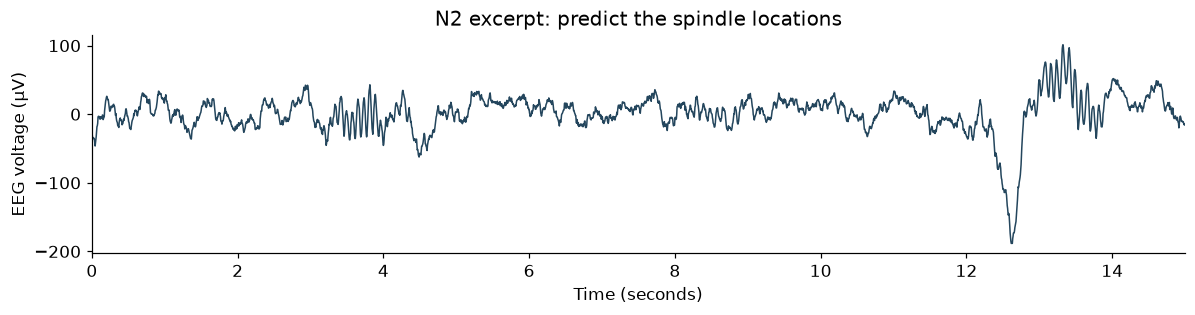

In [3]:
spindle_path = yasa.fetch_sample("N2_spindles_15sec_200Hz.txt")
spindle_data = np.loadtxt(spindle_path)
spindle_sf = 200.0
spindle_times = np.arange(spindle_data.size) / spindle_sf
print(f"Duration: {spindle_data.size / spindle_sf:.1f} s | units: µV")

fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(spindle_times, spindle_data, color="#24465D", lw=1)
ax.set(xlabel="Time (seconds)", ylabel="EEG voltage (µV)",
       xlim=(0, spindle_times[-1]), title="N2 excerpt: predict the spindle locations")
fig.tight_layout()
plt.show()

## 2. Run the detector

`yasa.spindles_detect` proposes events under stated frequency, threshold
and duration rules. Here we retain YASA's usual **12–15 Hz** spindle band
and **1–30 Hz** broadband range. The short curated excerpt is N2 throughout;
a full recording should use a reviewed hypnogram to select relevant stages.

The three criteria ask different questions:

| Criterion | What it checks | Parameter used here |
|---|---|---|
| Relative sigma power | Is enough of the broadband power in the spindle band? | `rel_pow=0.2` (20%) |
| Moving correlation | Does the broadband trace resemble its sigma-filtered component? | `corr=0.65` |
| Moving RMS | Is the sigma signal sufficiently strong compared with its background? | `rms=1.5` (a multiplier, not µV) |

YASA also checks event duration and merges nearby candidates. The detailed
calculations stay in the upstream tutorial; this lesson focuses on running
the public detector and inspecting its output.

In [4]:
baseline_thresholds = {"rel_pow": 0.2, "corr": 0.65, "rms": 1.5}
spindle_band = (12, 15)
broadband = (1, 30)
sp_baseline = yasa.spindles_detect(
    spindle_data, spindle_sf, freq_sp=spindle_band,
    freq_broad=broadband, thresh=baseline_thresholds,
)
spindle_columns = [
    "Start", "Peak", "End", "Duration", "Amplitude", "AmpFiltered",
    "RMS", "AbsPower", "RelPower", "Frequency", "Oscillations",
    "Symmetry", "Channel", "IdxChannel",
]
spindle_events = (sp_baseline.summary() if sp_baseline is not None
                  else pd.DataFrame(columns=spindle_columns))
print("Baseline events in this excerpt:", len(spindle_events))

Baseline events in this excerpt: 2


## 3. Inspect detections and event properties

The helper below draws the **same 15-second window** for every comparison.
Colored segments show the detector's event mask; the lower panel shows the
sigma-filtered signal. Filtering is for this display and does not replace
inspection of the broadband signal.

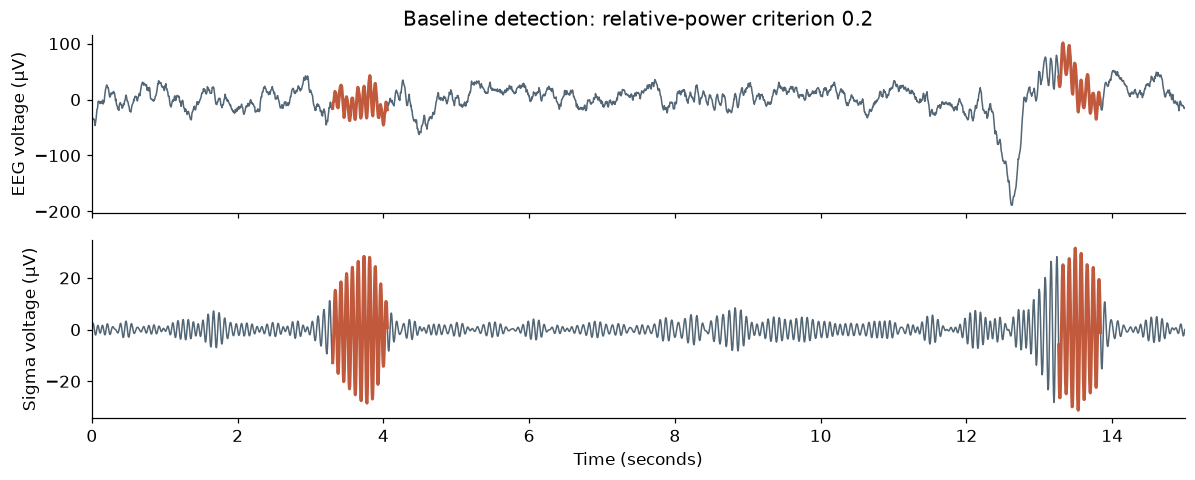

In [5]:
spindle_sigma = filter_data(
    spindle_data, spindle_sf, 12, 15,
    l_trans_bandwidth=1.5, h_trans_bandwidth=1.5, verbose=False,
)

def plot_spindle_overlay(result, title):
    """Display one detection result without changing the input or baseline."""
    mask = (np.asarray(result.get_mask()).squeeze().astype(bool)
            if result is not None else np.zeros(spindle_data.size, dtype=bool))
    fig, axes = plt.subplots(2, 1, figsize=(11, 4.5), sharex=True)
    for ax, signal, label in zip(
        axes, [spindle_data, spindle_sigma],
        ["EEG voltage (µV)", "Sigma voltage (µV)"],
    ):
        ax.plot(spindle_times, signal, color="#526675", lw=1)
        ax.plot(spindle_times, np.where(mask, signal, np.nan), color="#C15A3D", lw=2)
        ax.set(ylabel=label, xlim=(0, spindle_times[-1]))
    axes[0].set_title(title)
    axes[-1].set_xlabel("Time (seconds)")
    fig.tight_layout()
    plt.show()

plot_spindle_overlay(sp_baseline, "Baseline detection: relative-power criterion 0.2")

Locate one colored event in the plot and find its row below. These columns
answer different questions:

| Variable | Unit | Meaning |
|---|---|---|
| `Start` | seconds | Event start relative to the beginning of this excerpt |
| `Duration` | seconds | Event end minus event start |
| `Amplitude` | µV | Peak-to-peak amplitude in the detrended broadband signal |
| `AmpFiltered` | µV | Peak-to-peak amplitude in the sigma-filtered signal |
| `RMS` | µV | Root mean square: a summary of signal magnitude |
| `Frequency` | Hz | Median instantaneous frequency of the spindle |

In [6]:
inspect_columns = ["Start", "Duration", "Amplitude", "AmpFiltered", "RMS", "Frequency"]
display(spindle_events[inspect_columns].round(3))

,Start,Duration,Amplitude,AmpFiltered,RMS,Frequency
0,3.305,0.750,82.423,56.763,19.440,12.853
1,13.265,0.575,98.858,62.684,24.785,12.152


## 4. Try it: change one criterion 

**Predict:** what might happen when the relative-power criterion rises
from **0.2 to 0.8**? Make the change in the parameter cell after the helper.
The frequency bands, correlation/RMS criteria, input and plot window remain
fixed. `sp_baseline` and `spindle_events` retain the original result.

The function returns a table even when no events pass. An empty result is
useful evidence about this parameter choice, not a failed calculation.

In [7]:
def try_spindle_threshold(relative_power=0.2):
    """Rerun one criterion, inspect the same window and return event rows."""
    relative_power = float(relative_power)
    if not 0 <= relative_power <= 1:
        raise ValueError("Relative power must be a fraction between 0 and 1.")
    trial_thresholds = {"rel_pow": relative_power, "corr": 0.65, "rms": 1.5}
    result = yasa.spindles_detect(
        spindle_data, spindle_sf, freq_sp=spindle_band,
        freq_broad=broadband, thresh=trial_thresholds,
    )
    events = (result.summary() if result is not None
              else pd.DataFrame(columns=spindle_columns))
    print(f"Baseline: {len(spindle_events)} events | criterion {relative_power:.1f}: {len(events)} events")
    plot_spindle_overlay(result, f"Relative-power criterion {relative_power:.1f}")
    display(events[inspect_columns].round(3))
    return events

Baseline: 2 events | criterion 0.2: 2 events


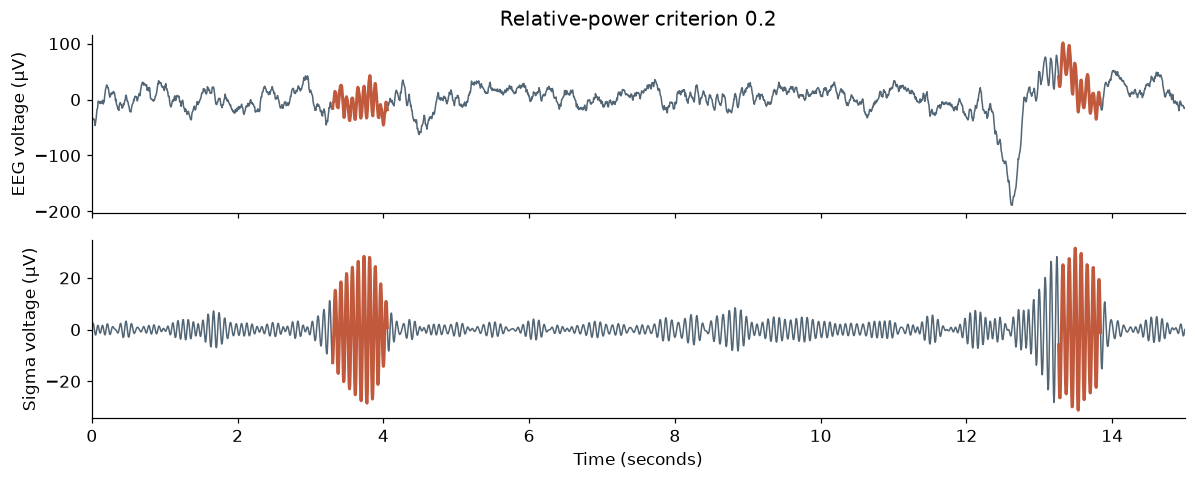

,Start,Duration,Amplitude,AmpFiltered,RMS,Frequency
0,3.305,0.750,82.423,56.763,19.440,12.853
1,13.265,0.575,98.858,62.684,24.785,12.152


In [8]:
# Change 0.2 to 0.8, predict the outcome, then rerun this cell.
relative_power_threshold = 0.2
trial_events = try_spindle_threshold(relative_power_threshold)

Changing a detector setting changes the operational selection; it does not
change the recorded physiology. Count is also different from density:
density needs a defined amount of eligible sleep time. This 15-second
illustration does not estimate a participant's full-night spindle density.

### Optional control panel

Move the slider, then press **Run detector**. The button deliberately
waits for you; moving the slider alone does not rerun the analysis.

In [9]:
if widgets is None:
    print("Use the parameter cell or try_spindle_threshold(0.8).")
else:
    spindle_slider = widgets.FloatSlider(
        value=0.2, min=0.1, max=0.9, step=0.1,
        description="Rel. power", readout_format=".1f", continuous_update=False,
    )
    spindle_button = widgets.Button(description="Run detector")
    spindle_output = widgets.Output()

    def on_spindle_click(_):
        spindle_output.clear_output(wait=True)
        with spindle_output:
            try_spindle_threshold(spindle_slider.value)

    spindle_button.on_click(on_spindle_click)
    display(widgets.VBox([spindle_slider, spindle_button, spindle_output]))

## 5. Keep an analysis record

Save the **baseline** event table and its settings. Trial runs are for
exploration; they do not overwrite the baseline. A future comparison
should report channel/reference, sleep-stage eligibility and settings,
together with amplitude, duration and density as separate measurements.

In [10]:
spindle_events.to_csv(OUT / "spindle_events.csv", index=False)
spindle_analysis = {
    "source_notebook": "01_spindles_detection.ipynb",
    "sample": Path(spindle_path).name,
    "sampling_rate_hz": spindle_sf,
    "input_units": "uV",
    "duration_seconds": spindle_data.size / spindle_sf,
    "sleep_context": "Curated 15-second N2 excerpt; no continuous hypnogram supplied",
    "spindle_band_hz": list(spindle_band),
    "broadband_hz": list(broadband),
    "baseline_thresholds": baseline_thresholds,
    "baseline_event_count": len(spindle_events),
    "full_night_density_estimated": False,
    "yasa_version": yasa.__version__,
}
(OUT / "analysis.json").write_text(json.dumps(spindle_analysis, indent=2) + "\n")
print("Baseline results saved in:", OUT)

Baseline results saved in: /private<repository>/outputs/three_notebook_workshop/01_spindles_detection


## 6. Take-home

* A detected spindle is an event selected under explicit criteria.
* Peak-to-peak amplitude, RMS, duration, frequency and density describe
  different properties. A rise in total sigma power can reflect larger,
  longer or more frequent bursts, as well as background activity.
* Inspect the signal and the event boundaries when comparing settings.

### Optional: an excerpt without spindles

The original notebook also supplies a **30-second N3 excerpt at 100 Hz**
selected to contain no spindles. Inspect it before running the same public
detector. An absence of detections on one selected excerpt is not a
validation of overall specificity, and N3 can contain spindles.

15-Nov-26 11:00:23 | WARNING | No spindle were found in channel CHAN000.


15-Nov-26 11:00:23 | WARNING | No spindles were found in data. Returning None.


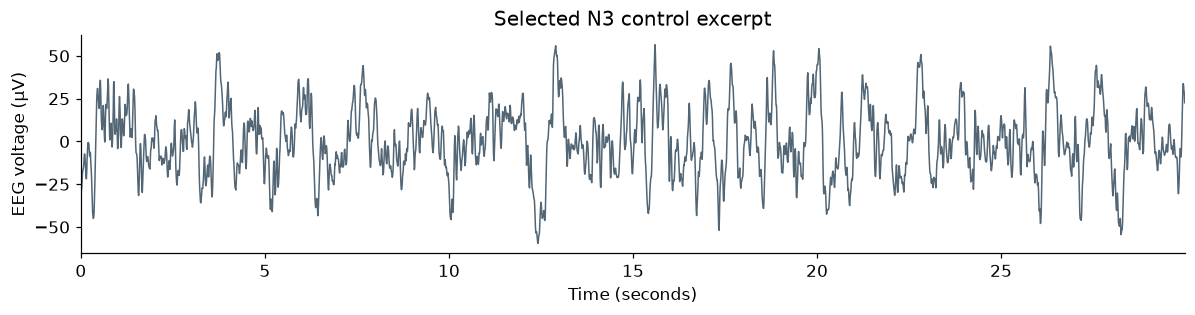

Detected events in this control excerpt: 0


,Start,Duration,Amplitude,AmpFiltered,RMS,Frequency


In [11]:
control_path = yasa.fetch_sample("N3_no-spindles_30sec_100Hz.txt")
control_data = np.loadtxt(control_path)
control_sf = 100.0
control_times = np.arange(control_data.size) / control_sf
control_result = yasa.spindles_detect(
    control_data, control_sf, freq_sp=spindle_band,
    freq_broad=broadband, thresh=baseline_thresholds,
)
control_events = (control_result.summary() if control_result is not None
                  else pd.DataFrame(columns=spindle_columns))
control_mask = (np.asarray(control_result.get_mask()).squeeze().astype(bool)
                if control_result is not None else np.zeros(control_data.size, dtype=bool))
fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(control_times, control_data, color="#526675", lw=1)
ax.plot(control_times, np.where(control_mask, control_data, np.nan), color="#C15A3D", lw=2)
ax.set(xlabel="Time (seconds)", ylabel="EEG voltage (µV)",
       xlim=(0, control_times[-1]), title="Selected N3 control excerpt")
fig.tight_layout()
plt.show()
print("Detected events in this control excerpt:", len(control_events))
display(control_events[inspect_columns].round(3))

## Sources and attribution

YASA: Raphael Vallat, Remington Mallett and contributors; BSD 3-Clause licence
(full license notice below). Sample data: [YASA dataset v1](https://zenodo.org/records/14564285).

## Upstream software license notice

YASA retains its upstream license. The notice is reproduced here so this notebook does not depend on a separate license file.

```text
BSD 3-Clause License

Copyright (c) 2018, Raphael Vallat
All rights reserved.

Redistribution and use in source and binary forms, with or without
modification, are permitted provided that the following conditions are met:

1. Redistributions of source code must retain the above copyright notice, this
   list of conditions and the following disclaimer.

2. Redistributions in binary form must reproduce the above copyright notice,
   this list of conditions and the following disclaimer in the documentation
   and/or other materials provided with the distribution.

3. Neither the name of the copyright holder nor the names of its
   contributors may be used to endorse or promote products derived from
   this software without specific prior written permission.

THIS SOFTWARE IS PROVIDED BY THE COPYRIGHT HOLDERS AND CONTRIBUTORS "AS IS"
AND ANY EXPRESS OR IMPLIED WARRANTIES, INCLUDING, BUT NOT LIMITED TO, THE
IMPLIED WARRANTIES OF MERCHANTABILITY AND FITNESS FOR A PARTICULAR PURPOSE ARE
DISCLAIMED. IN NO EVENT SHALL THE COPYRIGHT HOLDER OR CONTRIBUTORS BE LIABLE
FOR ANY DIRECT, INDIRECT, INCIDENTAL, SPECIAL, EXEMPLARY, OR CONSEQUENTIAL
DAMAGES (INCLUDING, BUT NOT LIMITED TO, PROCUREMENT OF SUBSTITUTE GOODS OR
SERVICES; LOSS OF USE, DATA, OR PROFITS; OR BUSINESS INTERRUPTION) HOWEVER
CAUSED AND ON ANY THEORY OF LIABILITY, WHETHER IN CONTRACT, STRICT LIABILITY,
OR TORT (INCLUDING NEGLIGENCE OR OTHERWISE) ARISING IN ANY WAY OUT OF THE USE
OF THIS SOFTWARE, EVEN IF ADVISED OF THE POSSIBILITY OF SUCH DAMAGE.
```